<a href="https://colab.research.google.com/github/madrudra2004/Demand-Forecasting-and-Strategic-product-Expansion/blob/main/Data%20wrangling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import iqr
from statsmodels.tsa.seasonal import seasonal_decompose
from collections import Counter
from itertools import combinations
from google.colab import drive
import itertools
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.metrics import r2_score, mean_squared_error,mean_absolute_error, mean_absolute_percentage_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import kpss
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.discrete.conditional_models import ConditionalLogit
import warnings
warnings.filterwarnings("ignore")
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
DF = pd.read_csv("/content/drive/MyDrive/23f1000625_BDM/Sales Metadata.csv")

In [ ]:
DF.head()

,DATE,MONTH YEAR,BILL NO,UNIQUE ID,CUSTOMER,ITEM NAME,CATEGORY,RATE,QTY,TOTAL
0,1/4/24,2024-04,1,2024-04:1,Santhosh,Leaf Ganesh (DF),Statue,"2,350.00",1.0,"2,350.00"
1,1/4/24,2024-04,2,2024-04:2,Hema Mahesh,Krishna 0.900,Statue,"1,698.00",1.0,"1,698.00"
2,3/4/24,2024-04,3,2024-04:3,Udayanoor Illam,Astalaxmi Tk2012 No.3,Home Decor,832.00,1.0,832.50
3,3/4/24,2024-04,3,2024-04:3,Udayanoor Illam,Br Arti Plate Plain Muj-6,Pooja,209.00,1.0,209.00
4,3/4/24,2024-04,3,2024-04:3,Udayanoor Illam,Astalaxmi Tk2010 No.4,Home Decor,971.00,1.0,971.04


In [ ]:
DF["DATE"] = pd.to_datetime(DF["DATE"], format="%d/%m/%y")

In [ ]:
DF['DATE'].min(), DF['DATE'].max()

(Timestamp('2024-04-01 00:00:00'), Timestamp('2025-07-31 00:00:00'))

In [ ]:
DF.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2704 entries, 0 to 2703
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   DATE        2704 non-null   datetime64[ns]
 1   MONTH YEAR  2704 non-null   object        
 2   BILL NO     2704 non-null   int64         
 3   UNIQUE ID   2704 non-null   object        
 4   CUSTOMER    2704 non-null   object        
 5   ITEM NAME   2704 non-null   object        
 6   CATEGORY    2704 non-null   object        
 7   RATE        2704 non-null   object        
 8   QTY         2704 non-null   float64       
 9   TOTAL       2704 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(7)
memory usage: 211.4+ KB


In [ ]:
DF['CATEGORY'] = DF['CATEGORY'].replace({'Home decor': 'Home Decor'})
DF['BILL NO'] = DF['BILL NO'].astype('object')
DF['RATE'] = DF['RATE'].replace(',', '', regex=True)
DF['TOTAL'] = DF['TOTAL'].replace(',', '', regex=True)


DF['RATE'] = pd.to_numeric(DF['RATE'], errors='coerce')
DF['TOTAL'] = pd.to_numeric(DF['TOTAL'], errors='coerce')
DF['QTY'] = pd.to_numeric(DF['QTY'], errors='coerce')

DF['DATE'] = pd.to_datetime(DF['DATE'])
DF['DAY'] = pd.to_datetime(DF['DATE']).dt.day_of_week

In [ ]:
#Handling Missing Values
DF.isna().sum()

,0
DATE,0
MONTH YEAR,0
BILL NO,0
UNIQUE ID,0
CUSTOMER,0
ITEM NAME,0
CATEGORY,0
RATE,0
QTY,0
TOTAL,0


In [ ]:
#Handling Duplicates
DF = DF.drop_duplicates()
display(DF.duplicated().sum())

np.int64(0)

In [ ]:
DF.head()

,DATE,MONTH YEAR,BILL NO,UNIQUE ID,CUSTOMER,ITEM NAME,CATEGORY,RATE,QTY,TOTAL,DAY
0,2024-04-01,2024-04,1,2024-04:1,Santhosh,Leaf Ganesh (DF),Statue,2350.0,1.0,2350.00,0
1,2024-04-01,2024-04,2,2024-04:2,Hema Mahesh,Krishna 0.900,Statue,1698.0,1.0,1698.00,0
2,2024-04-03,2024-04,3,2024-04:3,Udayanoor Illam,Astalaxmi Tk2012 No.3,Home Decor,832.0,1.0,832.50,2
3,2024-04-03,2024-04,3,2024-04:3,Udayanoor Illam,Br Arti Plate Plain Muj-6,Pooja,209.0,1.0,209.00,2
4,2024-04-03,2024-04,3,2024-04:3,Udayanoor Illam,Astalaxmi Tk2010 No.4,Home Decor,971.0,1.0,971.04,2


In [ ]:
DF.describe().T

,count,mean,min,25%,50%,75%,max,std
DATE,2703,2024-12-03 17:36:57.536071168,2024-04-01 00:00:00,2024-08-14 00:00:00,2024-12-03 00:00:00,2025-04-12 00:00:00,2025-07-31 00:00:00,NaN
RATE,2703.0,1530.494177,30.0,283.5,680.0,1700.0,31050.0,2733.475641
QTY,2703.0,1.337514,0.05,1.0,1.0,1.0,73.23,2.789033
TOTAL,2703.0,1726.584528,30.0,310.0,725.0,1920.1,73815.84,3511.540097
DAY,2703.0,3.337033,0.0,2.0,4.0,5.0,6.0,2.001661


In [ ]:
daily_sales = pd.DataFrame(DF.groupby('DATE')['TOTAL'].sum())
daily_sales.head()

,TOTAL
DATE,
2024-04-01,4048.00
2024-04-03,7540.71
2024-04-04,50430.62
2024-04-05,10742.33
2024-04-06,14802.40


In [ ]:
daily_sales = daily_sales.sort_index()
print('Start Date:',daily_sales.index.min(),
      '\nEnd Date:',daily_sales.index.max())

Start Date: 2024-04-01 00:00:00 
End Date: 2025-07-31 00:00:00


In [ ]:
daily_sales.head()

,TOTAL
DATE,
2024-04-01,4048.00
2024-04-03,7540.71
2024-04-04,50430.62
2024-04-05,10742.33
2024-04-06,14802.40


In [ ]:
daily_sales.index.nunique()

422

In [ ]:
#Splitting into training and test data
h = 30
train = daily_sales['TOTAL'][:-h]
test  = daily_sales['TOTAL'][-h:]
display(train.shape,test.shape)

(392,)

(30,)

In [ ]:
train.head()

,TOTAL
DATE,
2024-04-01,4048.00
2024-04-03,7540.71
2024-04-04,50430.62
2024-04-05,10742.33
2024-04-06,14802.40


In [ ]:
# Performing stationarity test to determine differencing order
adf_test = adfuller(train)
print(adf_test[1])

7.419155573113799e-18


as p value is < 0.05, the series is already stationary, therefore does not need differencing

# SARIMAX WITH EXOG

In [ ]:
train_w = train.copy()
upper = train.quantile(0.90)
train_w[train_w > upper] = upper

In [ ]:
y_train_log = np.log1p(train_w)
y_test_log  = np.log1p(test)   # only for alignment, not model fitting

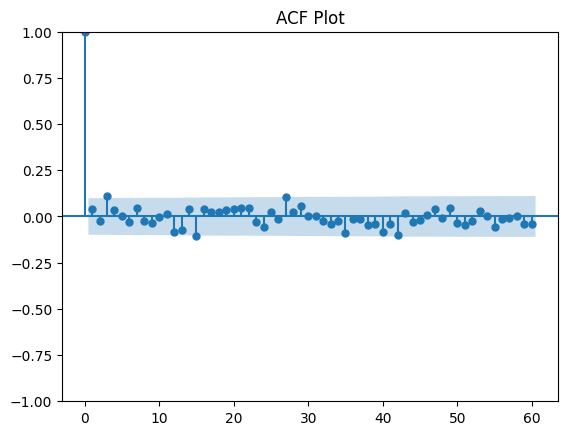

In [ ]:
plot_acf(train, lags=60)
plt.title("ACF Plot")
plt.show()

<Figure size 800x400 with 0 Axes>

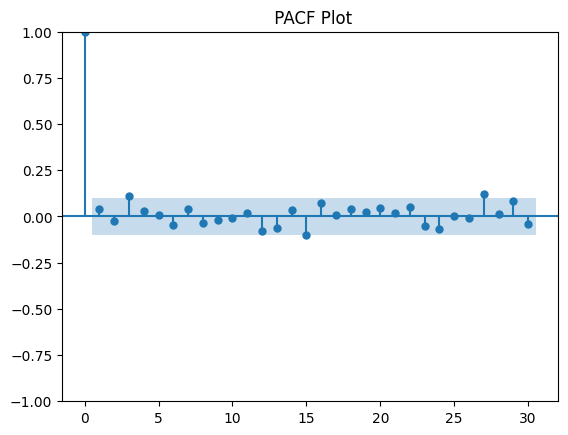

In [ ]:
plt.figure(figsize=(8,4))
plot_pacf(train, lags=30, method='ywm')
plt.title(" PACF Plot")
plt.show()


*   This means there is no strong direct dependence of today’s sales on specific past days.
*   The autoregressive effect is weak ( p = 0,1)



In [ ]:
def create_exog(series):
    idx = series.index
    exog = pd.DataFrame(index=idx)

    #Weekdays
    exog['dow'] = idx.weekday
    exog['is_weekend'] = idx.weekday.isin([5, 6]).astype(int)

    #Month effects
    exog['is_month_start'] = idx.day.isin([1,2,3,4,5]).astype(int)
    exog['is_month_end'] = idx.day >= 25
    exog['is_mid_month'] = idx.day.isin([14,15,16]).astype(int)

    # Festival windows
    exog['is_diwali_window'] = idx.month.isin([10,11]).astype(int)
    exog['is_ganesh_window'] = idx.month.isin([8,9]).astype(int)
    exog['is_newyear_window'] = idx.month.isin([1]).astype(int)
    exog['is_ugadi_window'] = idx.month.isin([3,4]).astype(int)
    exog['is_akshaya_window'] = idx.month.isin([4,5]).astype(int)

    # Interaction effects
    exog['weekend_month_end'] = exog['is_weekend'] & exog['is_month_end']
    exog['weekend_festival'] = exog['is_weekend'] & (
        exog['is_diwali_window'] | exog['is_ganesh_window'] | exog['is_newyear_window'] |
        exog['is_ugadi_window'] | exog['is_akshaya_window']
    )


    exog = pd.get_dummies(exog, columns=['dow'], drop_first=True)

    return exog.astype(float)

In [ ]:
exog_train = create_exog(y_train_log)
exog_test  = create_exog(y_test_log)

# Align columns
exog_test = exog_test.reindex(columns=exog_train.columns, fill_value=0)

In [ ]:
exog_train.shape, exog_test.shape

((392, 17), (30, 17))

In [ ]:
exog_train.head()

,is_weekend,is_month_start,is_month_end,is_mid_month,is_diwali_window,is_ganesh_window,is_newyear_window,is_ugadi_window,is_akshaya_window,weekend_month_end,weekend_festival,dow_1,dow_2,dow_3,dow_4,dow_5,dow_6
DATE,,,,,,,,,,,,,,,,,
2024-04-01,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2024-04-03,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2024-04-04,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2024-04-05,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2024-04-06,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
train_data = pd.concat([y_train_log, exog_train], axis=1).dropna()

y_train_final = train_data.iloc[:, 0]
exog_train_final = train_data.iloc[:, 1:]

In [ ]:
y_train_final.shape, exog_train_final.shape

((392,), (392, 17))

In [ ]:
model = SARIMAX(
    y_train_final,
    exog=exog_train_final,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = model.fit(disp=False)
print(results.summary())

                                     SARIMAX Results                                     
Dep. Variable:                             TOTAL   No. Observations:                  392
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood                -632.665
Date:                           Fri, 16 Jan 2026   AIC                           1309.331
Time:                                   05:03:01   BIC                           1396.187
Sample:                                        0   HQIC                          1343.785
                                           - 392                                         
Covariance Type:                             opg                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
is_weekend            1.0805      0.187      5.764      0.000       0.713       1.448
is_month_start       -

In [ ]:
# 1. Get forecast in log space
forecast_res = results.get_forecast(
    steps=len(test),
    exog=exog_test.iloc[-len(test):]
)

forecast_log = forecast_res.predicted_mean
forecast_ci_log = forecast_res.conf_int()

# 2. 🔴 Bias correction for log transform (THIS IS CRITICAL)
# variance of forecast mean in log space
sigma2 = forecast_res.var_pred_mean

# Bias-corrected inverse transform
forecast = np.expm1(forecast_log + 0.5 * sigma2)

ci_lower = np.expm1(forecast_ci_log.iloc[:, 0])
ci_upper = np.expm1(forecast_ci_log.iloc[:, 1])

# 3. Enforce coherent caps (mean AND CI)
cap = upper  # same cap used for training

forecast = forecast.clip(lower=0, upper=cap)
ci_lower = ci_lower.clip(lower=0)
ci_upper = ci_upper.clip(upper=cap)


In [ ]:
rmse = np.sqrt(mean_squared_error(test, forecast))
mae  = mean_absolute_error(test, forecast)
relative_error_pct = (mae / test.sum()) * 100

print(f"RMSE: {rmse:,.0f}")
print(f"MAE : {mae:,.0f}")
print(f"Relative Accuracy: {relative_error_pct:.2f}%")

RMSE: 9,825
MAE : 7,695
Relative Accuracy: 3.04%


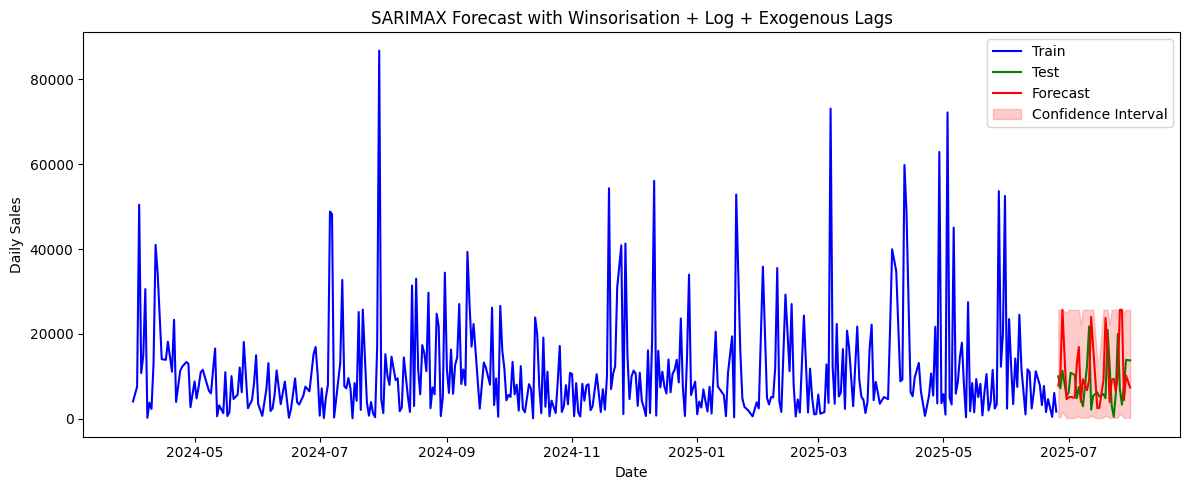

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(train.index, train, label='Train', color='blue')
plt.plot(test.index, test, label='Test', color='green')
plt.plot(test.index, forecast, label='Forecast', color='red')

plt.fill_between(
    test.index,
    ci_lower,
    ci_upper,
    color='red',
    alpha=0.2,
    label='Confidence Interval'
)

plt.title('SARIMAX Forecast with Winsorisation + Log + Exogenous Lags')
plt.xlabel('Date')
plt.ylabel('Daily Sales')
plt.legend()
plt.tight_layout()
plt.show()

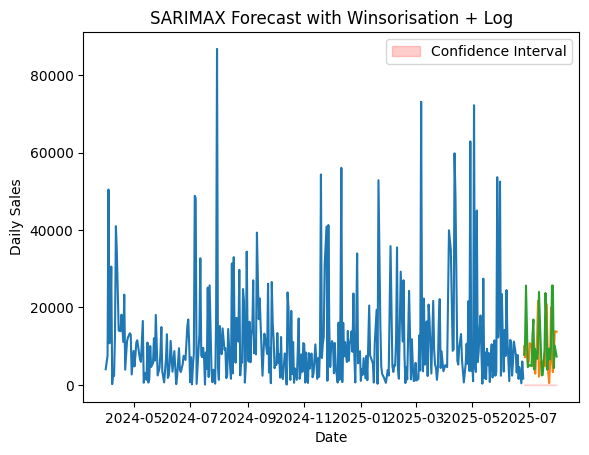

In [ ]:
plt.plot(train.index, train)
plt.plot(test.index, test)
plt.plot(test.index, forecast)

plt.fill_between(
    test.index,
    forecast_ci_log.iloc[:, 0],
    forecast_ci_log.iloc[:, 1],
    color='red',
    alpha=0.2,
    label='Confidence Interval'
)

plt.title('SARIMAX Forecast with Winsorisation + Log')
plt.xlabel('Date')
plt.ylabel('Daily Sales')
plt.legend()
plt.show()

# CATEGORY WISE DEMAND FORECASTING

In [ ]:
DF.head()

,DATE,MONTH YEAR,BILL NO,UNIQUE ID,CUSTOMER,ITEM NAME,CATEGORY,RATE,QTY,TOTAL,DAY
0,2024-04-01,2024-04,1,2024-04:1,Santhosh,Leaf Ganesh (DF),Statue,2350.0,1.0,2350.00,0
1,2024-04-01,2024-04,2,2024-04:2,Hema Mahesh,Krishna 0.900,Statue,1698.0,1.0,1698.00,0
2,2024-04-03,2024-04,3,2024-04:3,Udayanoor Illam,Astalaxmi Tk2012 No.3,Home Decor,832.0,1.0,832.50,2
3,2024-04-03,2024-04,3,2024-04:3,Udayanoor Illam,Br Arti Plate Plain Muj-6,Pooja,209.0,1.0,209.00,2
4,2024-04-03,2024-04,3,2024-04:3,Udayanoor Illam,Astalaxmi Tk2010 No.4,Home Decor,971.0,1.0,971.04,2


In [ ]:
category_daily = (
    DF.groupby(['CATEGORY', 'DATE'])['TOTAL']
      .sum()
      .reset_index()
)

In [ ]:
category_daily.head()

,CATEGORY,DATE,TOTAL
0,Home Decor,2024-04-03,5649.65
1,Home Decor,2024-04-04,7429.82
2,Home Decor,2024-04-06,900.00
3,Home Decor,2024-04-07,171.00
4,Home Decor,2024-04-10,171.00


In [ ]:
category_daily['CATEGORY'].unique()

array(['Home Decor', 'Lamp', 'Pooja', 'Statue', 'Utensil'], dtype=object)

In [ ]:
category_dfs = {
    cat: category_daily[category_daily['CATEGORY'] == cat]
    for cat in category_daily['CATEGORY'].unique()
}
statue_df = category_dfs['Statue']
lamps_df = category_dfs['Lamp']
hd_df = category_dfs['Home Decor']
utensil_df = category_dfs['Utensil']
pooja_df = category_dfs['Pooja']

In [ ]:
statue_df.shape, lamps_df.shape, hd_df.shape, utensil_df.shape, pooja_df.shape

((291, 3), (294, 3), (259, 3), (190, 3), (232, 3))

In [ ]:
def make_continuous_ts(cat_df):
    ts = cat_df.set_index('DATE').asfreq('D')
    ts['TOTAL'] = ts['TOTAL'].fillna(0)
    return ts

category_ts = {
    cat: make_continuous_ts(df_cat)
    for cat, df_cat in category_dfs.items()
}

In [ ]:
exog_dict = {
    cat: create_exog(ts)
    for cat, ts in category_ts.items()
}

In [ ]:
horizon = 30  # forecast horizon

metrics = {}
forecasts = {}

In [ ]:
for cat in category_ts:

    print(f"\n===== CATEGORY: {cat} =====")

    ts = category_ts[cat]['TOTAL']
    exog = exog_dict[cat]

    # --- Train / test split ---
    y_train = ts.iloc[:-horizon]
    y_test = ts.iloc[-horizon:]

    X_train = exog.iloc[:-horizon]
    X_test = exog.iloc[-horizon:]

    # --- Refit model on TRAIN only (important) ---
    model = SARIMAX(
        y_train,
        exog=X_train,
        order=(1,0,1),
        seasonal_order=(1,0,1,7),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    results = model.fit(disp=False)

    print("\n--- SARIMAX Model Summary ---")
    print(results.summary())
    # --- Forecast ---
    forecast_res = results.get_forecast(
        steps=horizon,
        exog=X_test
    )

    y_pred = forecast_res.predicted_mean
    ci = forecast_res.conf_int()

    # --- Error metrics ---
    mae = mean_absolute_error(y_test, y_pred)
    total_sales_test = y_test.sum()
    relative_error_pct = (mae / total_sales_test) * 100
    relative_accuracy = 100 - relative_error_pct

    metrics[cat] = {
        "MAE": mae,
        "Relative Error %": relative_error_pct
    }

    forecasts[cat] = {
        "y_train": y_train,
        "y_test": y_test,
        "y_pred": y_pred,
        "ci": ci
    }

    print(f"MAE : {mae:,.0f}")
    print(f"Total Sales in Test: {total_sales_test:,.0f}")
    print(f"Relative Error: {relative_error_pct:.2f}%")



===== CATEGORY: Home Decor =====

--- SARIMAX Model Summary ---
                                     SARIMAX Results                                     
Dep. Variable:                             TOTAL   No. Observations:                  453
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood               -4274.608
Date:                           Thu, 15 Jan 2026   AIC                           8593.216
Time:                                   12:32:25   BIC                           8683.324
Sample:                               04-03-2024   HQIC                          8628.751
                                    - 06-29-2025                                         
Covariance Type:                             opg                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
is_weekend         1202.8813    594.842    

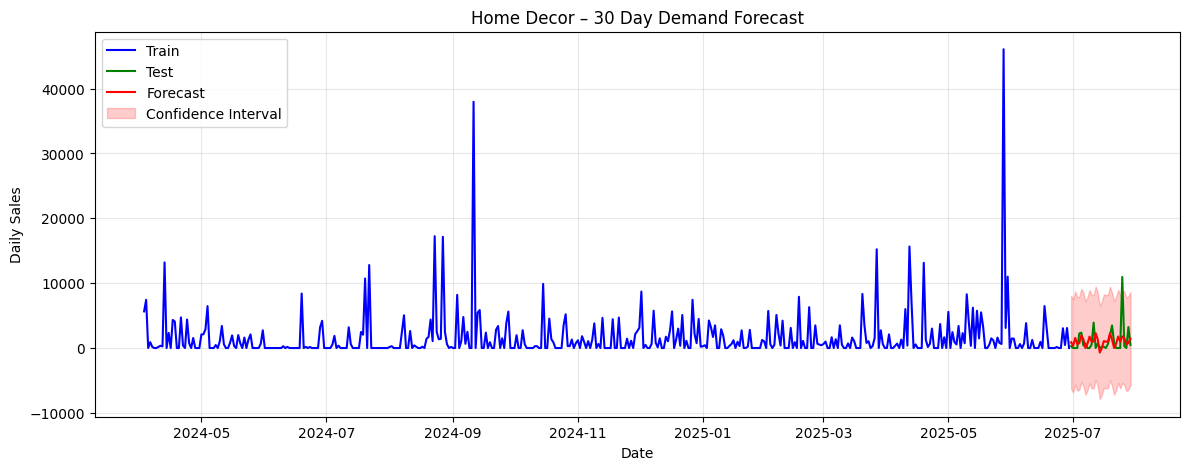

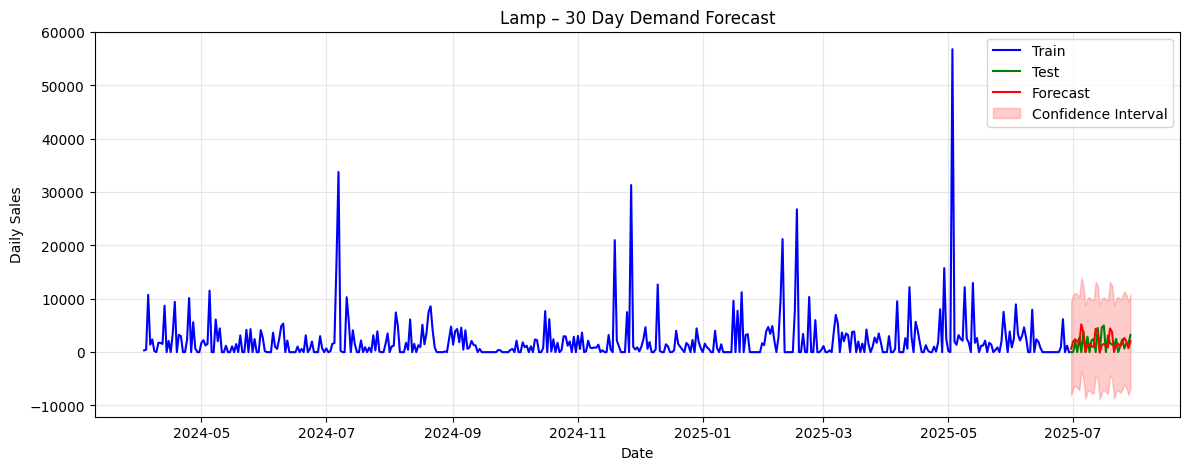

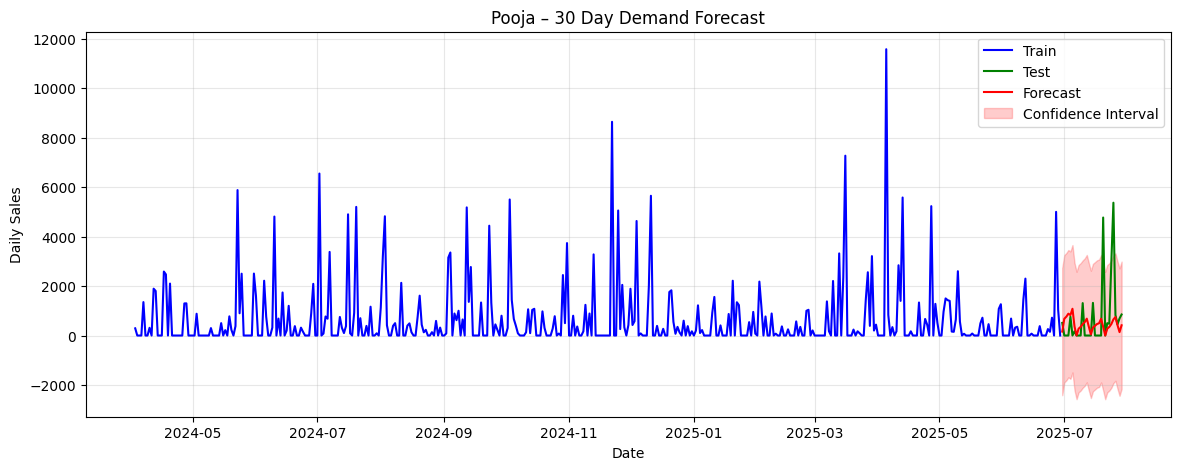

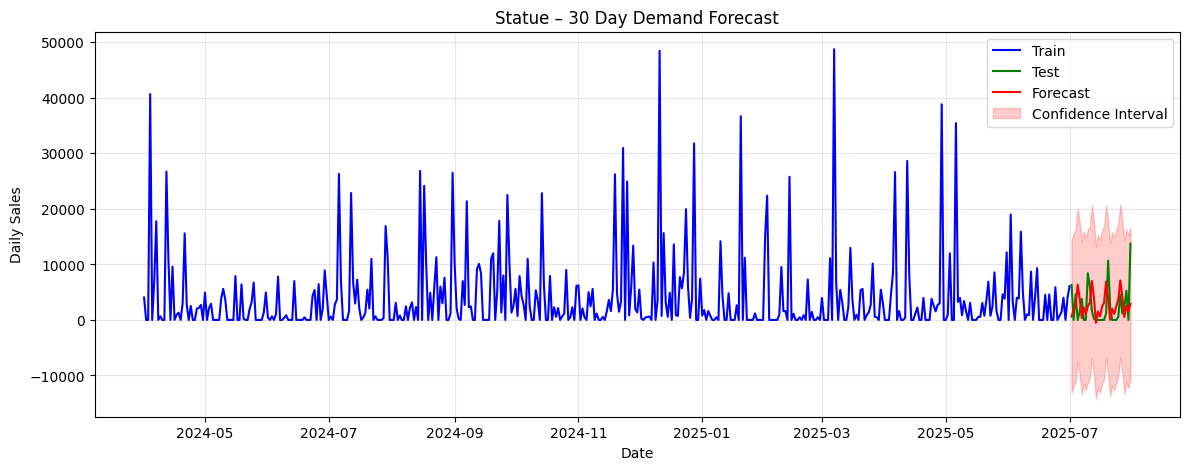

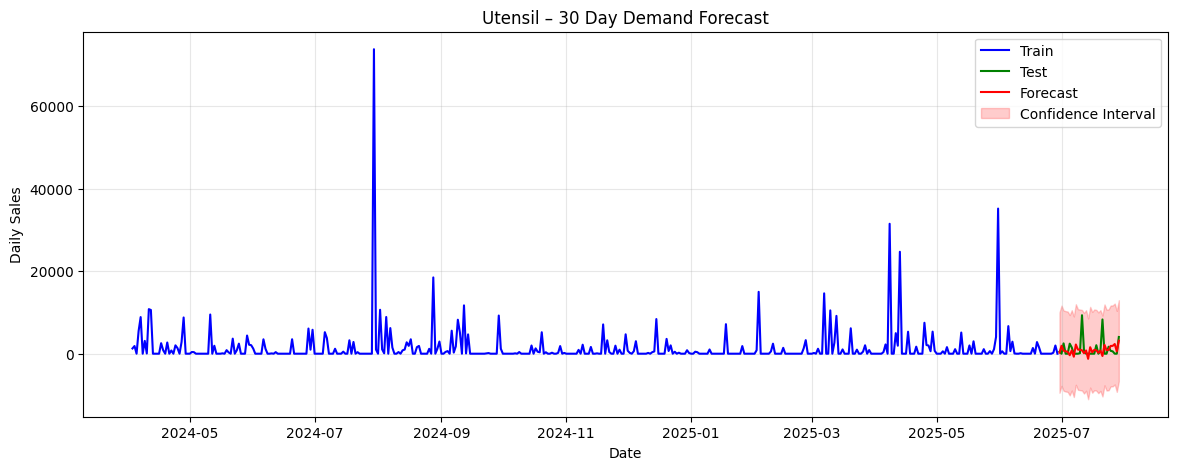

In [ ]:
for cat, data in forecasts.items():

    y_train = data["y_train"]
    y_test = data["y_test"]
    y_pred = data["y_pred"]
    ci = data["ci"]

    plt.figure(figsize=(14, 5))

    plt.plot(y_train.index, y_train, label="Train", color="blue")
    plt.plot(y_test.index, y_test, label="Test", color="green")
    plt.plot(y_pred.index, y_pred, label="Forecast", color="red")

    plt.fill_between(
        ci.index,
        ci.iloc[:, 0],
        ci.iloc[:, 1],
        color="red",
        alpha=0.2,
        label="Confidence Interval"
    )

    plt.title(f"{cat} – 30 Day Demand Forecast")
    plt.xlabel("Date")
    plt.ylabel("Daily Sales")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()


# CUSTOMER PROFILING

In [1]:
data = pd.read_csv('/content/drive/MyDrive/23f1000625_BDM/Customer Feedback survery - BDM.csv')
data.head()

NameError: name 'pd' is not defined

In [ ]:
data = data.drop_duplicates(
    subset='Full Name',
    keep='last'
)

In [ ]:
codes, uniques = pd.factorize(
    data['Full Name'].astype(str).str.strip(),
    sort=False
)

data['respondent_id'] = 'R' + (codes + 1).astype(str)

In [ ]:
data['respondent_id'].nunique() == data['Full Name'].nunique()

In [ ]:
data['respondent_id'].unique()

In [ ]:
#Converting the data to long format
product_map = {
    "Elegant Brass Lamp – 21 inches – ₹5,300": {
        "category": "Lamp",
        "size": "Medium",
        "price": "Medium"
    },
    "Bronze Thali set - 5000": {
        "category": "Utensil",
        "size": "Medium",
        "price": "Medium"
    },
    "Decorative Bronze/Brass Wall Hanging Ashtalakshmi – 42 inches – ₹6000": {
        "category": "Home Decor",
        "size": "Large",
        "price": "Medium"
    },
    "Handcrafted Bronze/Brass Statue – 13.5 inches – ₹8,800": {
        "category": "Statue",
        "size": "Medium",
        "price": "Medium"
    },
    "Decorative Brass Wall Art – 11 inches – ₹3,600":{
        "category": "Home Decor",
        "size": "Small",
        "price": "Low"
    },
    "Sacred Pooja Aarti – 5 inches BIG – ₹3,300":{
        "category": "Pooja",
        "size": "Large",
        "price": "Medium"
    },
    "Handcrafted Bronze/Brass Krishna with Stone work – 30 inches – ₹34,000":{
        "category": "Statue",
        "size": "Large",
        "price": "High"
    },
    "Elegant Brass Lamp – 48 inches (3ft) – ₹30,000":{
        "category": "Lamp",
        "size": "Large",
        "price": "High"
    },
    "Traditional Bronze Vessel Warp – 26 inches – ₹39,600" :{
        "category": "Utensil",
        "size": "Large",
        "price": "High"
    },
    "Handcrafted Bronze/Brass Ganesha – 5 inches – ₹2,800":{
        "category": "Statue",
        "size": "Small",
        "price": "Low"
    },
    "Sacred Pooja Set – 4 inches – ₹3500":{
        "category": "Pooja",
        "size": "Medium",
        "price": "Medium"
    },
    "Decorative Bronze Wall Art – ₹5,000":{
        "category": "Home Decor",
        "size": "Medium",
        "price": "Medium"
    },
    "Traditional Bronze Changazhi - 1500":{
        "category": "Utensil",
        "size": "Small",
        "price": "Low"
    },
    "Elegant Kamakshi Lamp – 5 inches – ₹890":{
        "category": "Lamp",
        "size": "Small",
        "price": "Low"
    },
    "Sacred Pooja Chandanam bowl – 4 inches – ₹450":{
        "category": "Pooja",
        "size": "Medium",
        "price": "Low"
    }}

In [ ]:
choice_design = {
    "A": [
        "Elegant Brass Lamp – 21 inches – ₹5,300",
        "Bronze Thali set - 5000",
        "Decorative Bronze/Brass Wall Hanging Ashtalakshmi – 42 inches – ₹6000"
    ],
    "B": [
        "Handcrafted Bronze/Brass Statue – 13.5 inches – ₹8,800",
        "Decorative Brass Wall Art – 11 inches – ₹3,600",
        "Sacred Pooja Aarti – 5 inches BIG – ₹3,300"
    ],
    "C": [
       "Handcrafted Bronze/Brass Krishna with Stone work – 30 inches – ₹34,000",
       "Elegant Brass Lamp – 48 inches (3ft) – ₹30,000",
       "Traditional Bronze Vessel Warp – 26 inches – ₹39,600"
    ],
    "D": [
        "Handcrafted Bronze/Brass Ganesha – 5 inches – ₹2,800",
        "Sacred Pooja Set – 4 inches – ₹3500",
        "Decorative Bronze Wall Art – ₹5,000"
    ],
    "E": [
         "Traditional Bronze Changazhi - 1500",
         "Elegant Kamakshi Lamp – 5 inches – ₹890",
         "Sacred Pooja Chandanam bowl – 4 inches – ₹450"
    ]
}

In [ ]:
#CREATING LONG FORMAT
rows = []

for _, r in data.iterrows():
    respondent = r["respondent_id"]

    for choice_set in ["A", "B", "C", "D", "E"]:

        chosen_product = r[f"{choice_set}."] # Corrected to include the period
        options = choice_design[choice_set]

        for option_id, product in enumerate(options, start=1):

            attrs = product_map[product]

            rows.append({
                "respondent_id": respondent,
                "choice_set": choice_set,
                "option_id": option_id,
                "category": attrs["category"],
                "size": attrs["size"],
                "price": attrs["price"],
                "chosen": int(product == chosen_product)
            })

In [ ]:
conjoint_df = pd.DataFrame(rows)
conjoint_df.columns

In [2]:
conjoint_df.groupby(
    ["respondent_id", "choice_set"]
)["chosen"].sum().value_counts()

NameError: name 'conjoint_df' is not defined

In [ ]:
conjoint_df['category'].unique(), conjoint_df['size'].unique(), conjoint_df['price'].unique()

In [ ]:
# Unique respondents
respondents = conjoint_df['respondent_id'].unique()

# 80:20 split at respondent level
train_resp, test_resp = train_test_split(
    respondents,
    test_size=0.2,
    random_state=42
)

In [ ]:
train_resp.shape, test_resp.shape

In [ ]:
train_df = conjoint_df[conjoint_df['respondent_id'].isin(train_resp)].copy()
test_df  = conjoint_df[conjoint_df['respondent_id'].isin(test_resp)].copy()

In [ ]:
# Features
X_train = pd.get_dummies(train_df[['category', 'size', 'price']])
X_test  = pd.get_dummies(test_df[['category', 'size', 'price']])

# Align columns (VERY IMPORTANT)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Target
y_train = train_df['chosen']
y_test  = test_df['chosen']

# Groups (choice-set level)
groups_train = (
    train_df['respondent_id'].astype(str) + "_" + train_df['choice_set']
)
groups_test = (
    test_df['respondent_id'].astype(str) + "_" + test_df['choice_set']
)

In [ ]:
model = ConditionalLogit(y_train, X_train, groups=groups_train)

result = model.fit_regularized(
    method="elastic_net",
    alpha=0.001,
    L1_wt=0.001
)
beta = result.params
print(beta)

In [ ]:
# Linear utility = X * beta
utilities = X_test @ beta
test_df = test_df.copy()
# Ensure the assigned column is numeric (explicitly cast to float)
test_df["utility"] = utilities.astype(float).values

test_df["exp_utility"] = np.exp(test_df["utility"])

test_df["pred_prob"] = (
    test_df
    .groupby(["respondent_id", "choice_set"])["exp_utility"]
    .transform(lambda x: x / x.sum())
)

In [3]:
test_df["hit"] = (
    (test_df["predicted_choice"] == 1) &
    (test_df["chosen"] == 1)
).astype(int)

total_choice_sets = test_df.groupby(
    ["respondent_id", "choice_set"]
).ngroups

hit_rate = (test_df["hit"].sum() / total_choice_sets) * 100

print(f"Hit Rate (Choice Prediction Accuracy): {hit_rate:.2f}%")

NameError: name 'test_df' is not defined

In [ ]:
coef = result.params.sort_values()

plt.figure(figsize=(8, 5))
coef.plot(kind='barh')
plt.axvline(0, color='black', linewidth=0.8)

plt.title("Conditional Logit Coefficients (Customer Preferences)")
plt.xlabel("Utility Weight")
plt.ylabel("Attribute Levels")
plt.tight_layout()
plt.show()

In [ ]:
coef_df = coef.reset_index()
coef_df.columns = ['attribute', 'value']

coef_df['group'] = coef_df['attribute'].str.split('_').str[0]

importance = coef_df.groupby('group')['value'].apply(
    lambda x: x.abs().sum()
)

importance = importance / importance.sum() * 100

importance.plot(kind='bar', figsize=(6,4))
plt.ylabel("Relative Importance (%)")
plt.title("Relative Importance of Product Attributes")
plt.tight_layout()
plt.show()